# Agreement between chemical graph proximity and spatial co-localization of ions

This notebook tests whether ions that are close in a chemical label graph are also spatially co-localized in tissue, and how well graph-propagated ion representations align with the empirical co-localization structure. It answers which graph variants encode relations that are consistent with what MSI images show, which is the condition under which graph-coupled classifiers can help a spatial representation rather than impose an unrelated chemical prior.

## Introduction

Chemical hierarchy expresses structural relatedness; tissue co-localization expresses shared biological distribution. The two need not agree: PC and PE species share the glycerophospholipid backbone but can be enriched in different cell types. If a graph links ions whose images are unrelated, generating their classifier weights from shared graph parameters couples tasks that the encoder must solve differently.

### Assumptions

- **Co-localization reference.** Pearson correlation of TIC-normalized ion images within an image, pooled over images by Fisher $z$ weighted with $n_i-3$. Pairs never annotated in the same image have no reference value.
- **Exchangeability.** The permutation test assumes ion labels are exchangeable under the null hypothesis; ion-pair values are not independent, which is why a permutation (Mantel) test is used instead of a parametric test of the correlation.
- **Rank Mantel statistic.** Graph similarity ranks are computed once over all pairs of usable ions; the statistic is the Pearson correlation between these ranks and the ranks of co-localization over co-observed pairs (a Spearman-type statistic; exact permutation without re-ranking).
- **Kernel alignment population.** Centered kernel alignment uses ions annotated in at least 3 images; missing co-localization entries are set to 0 (no evidence) with unit diagonal.

### Notation

- $\bar r_{ab}$ — pooled co-localization of ions $a,b$.
- $T(a,b)=w_a^\top w_b/(\lVert w_a\rVert^2+\lVert w_b\rVert^2-w_a^\top w_b)$ — Tanimoto similarity of closure membership vectors (Jaccard for binary memberships).
- $\rho$ — rank Mantel statistic between $T$ and $\bar r$; $p$ — one-sided permutation p-value ($B = 199$).
- $K_k$ — cosine kernel of rows of $\hat A^k$ for selected ions; $L$ — co-localization kernel; $\mathrm{CKA}(K_k,L)$ — centered kernel alignment.

In [1]:
from pathlib import Path

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from msi_autoencoder_wrapper.analysis.precompute.cli import run_precompute_command
from msi_autoencoder_wrapper.analysis.precompute.strategies.chemistry import class_graph_analysis as precompute
from msi_autoencoder_wrapper.visualization import chemistry as plots
from msi_autoencoder_wrapper.visualization.theme import resolve_theme

SETTINGS = precompute.read_settings(Path("analysis_settings.yaml"))
THEME = resolve_theme("diagnostic_light")
ANALYSIS = "graph_colocalization"
CONFIG = SETTINGS["analyses"][ANALYSIS]
COLLECTIONS = list(SETTINGS["collections"])
TAXONOMIES = SETTINGS["taxonomies"]["order"]
pd.set_option("display.width", 200, "display.max_columns", 40)


def table(name):
    """Load one canonical result table of this notebook's analysis."""
    return precompute.load_result(SETTINGS, ANALYSIS, name)


print("Precompute command:", run_precompute_command(SETTINGS["settings_path"], background=False), "--analysis", ANALYSIS)

2026-10-13 09:56:08,879 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 1 implementation module(s) in package 'msi_autoencoder_wrapper.binners.binners_strategies'.


2026-10-13 09:56:08,882 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 6 implementation module(s) in package 'msi_autoencoder_wrapper.binners.inverse_strategies'.


2026-10-13 09:56:09,292 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 3 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures.types.autoencoders.presets'.


2026-10-13 09:56:09,294 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 28 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures.types.autoencoders'.


2026-10-13 09:56:09,301 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 0 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures.types.schema'.


2026-10-13 09:56:09,302 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 46 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures'.


2026-10-13 09:56:09,320 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 2 implementation module(s) in package 'msi_autoencoder_wrapper.models.datasets.strategies'.


2026-10-13 09:56:09,335 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 29 implementation module(s) in package 'msi_autoencoder_wrapper.training.criterions.autoencoder'.


2026-10-13 09:56:09,336 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 33 implementation module(s) in package 'msi_autoencoder_wrapper.training.criterions'.


Precompute command: uv run --extra cu118 python -m msi_autoencoder_wrapper.analysis.precompute --settings /home/max/repositories/MSIAutoEncoderWrapper/assets/experiments/autoencoder_architecture/notebooks/GCN_expansion/analysis_settings.yaml --analysis graph_colocalization


## Co-localization of ion pairs as a function of graph similarity

### Methodology

#### Theoretical

Ion pairs are grouped by their graph similarity $T(a,b)$; if graph proximity reflects spatial behaviour, the co-localization distribution shifts upward with $T$. Pairs with $T=0$ (no shared class) are the reference.

#### Implementation

`pair_sample.csv` contains a seeded uniform sample of at most 20 000 co-observed ion pairs per focus variant (seed from settings); violins use the sample, which is stated in the figure title. Bins: $T=0$, $(0,0.25]$, $(0.25,0.5]$, $(0.5,0.75]$, $(0.75,1]$.

#### Figure descriptions

*Figure 1.* One panel per focus variant (selected collection); $x$: graph similarity bin; $y$: pooled co-localization $\bar r_{ab}$; each point is one sampled ion pair (at most 400 drawn per violin). The dashed line is the median co-localization of pairs with $T=0$. Upward shift with increasing $T$ means graph-related ions co-localize more.

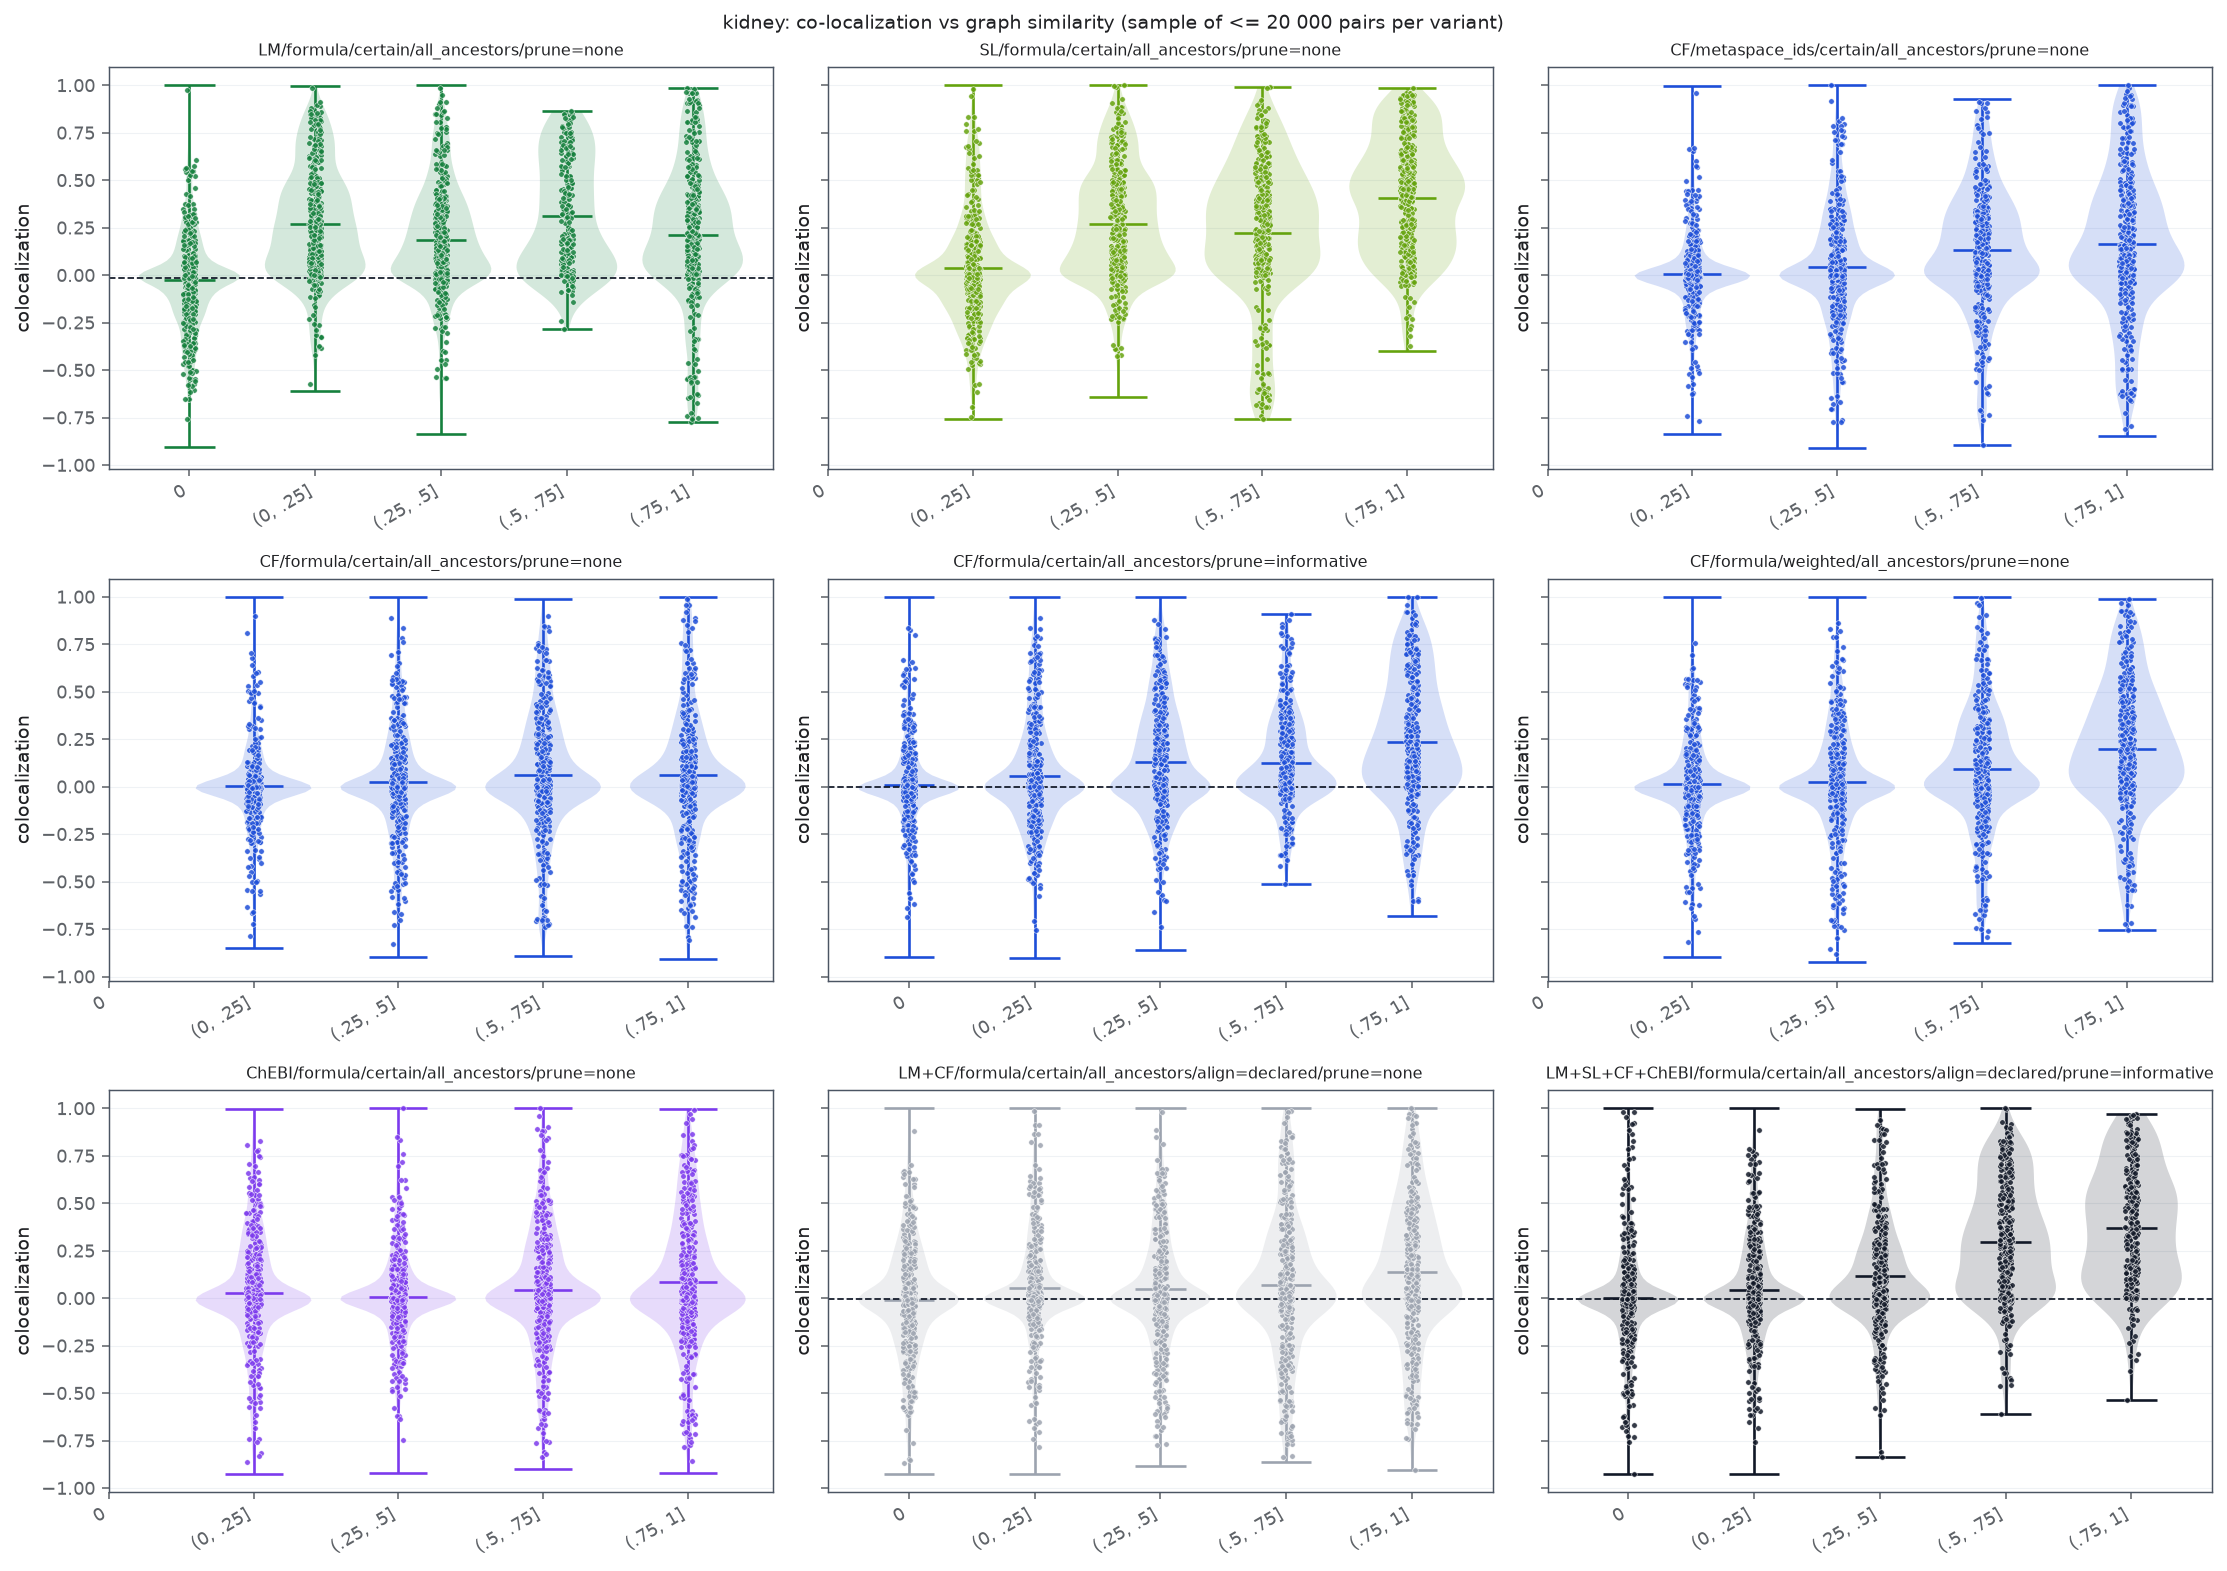

In [2]:
pairs = table("pair_sample.csv")

# --- what this figure shows -------------------------------------------------
COLLECTION = "kidney"
EDGES = [-0.001, 0.0, 0.25, 0.5, 0.75, 1.0]
LABELS = ["0", "(0, .25]", "(.25, .5]", "(.5, .75]", "(.75, 1]"]
# ---------------------------------------------------------------------------
subset = pairs[pairs.collection == COLLECTION].copy()
subset["bin"] = pd.cut(subset.similarity, EDGES, labels=LABELS).astype(str)
variants = list(dict.fromkeys(subset.variant_id))
columns = 3
figure, axes = plt.subplots(int(np.ceil(len(variants) / columns)), columns, figsize=(16, 3.8 * np.ceil(len(variants) / columns)),
                            sharey=True, squeeze=False)
for axis, variant in zip(axes.ravel(), variants):
    rows = subset[subset.variant_id == variant]
    reference = float(rows.loc[rows.bin == "0", "colocalization"].median()) if (rows.bin == "0").any() else None
    plots.violin_groups(axis, rows, group="bin", value="colocalization", order=LABELS,
                        colors={l: plots.taxonomy_color(variant.split("/")[0]) for l in LABELS}, reference=reference, theme=THEME)
    axis.set_title(variant.replace("/align=none", "").replace("/adduct=0", ""), fontsize=8)
for axis in axes.ravel()[len(variants):]:
    axis.set_axis_off()
figure.suptitle(f"{COLLECTION}: co-localization vs graph similarity (sample of <= 20 000 pairs per variant)", fontsize=10)
plt.tight_layout()

### Remarks

- Single-root taxonomies (ClassyFire, ChEBI) have no pairs with $T=0$ under all-ancestor closure, because every resolved ion shares the root; the dashed reference line is then absent.
- Co-localization rises with graph similarity most clearly for SwissLipids and LIPID MAPS (median ≈ 0 at $T=0$ to 0.25–0.40 at high $T$) and for the pruned four-taxonomy graph; for unpruned ClassyFire and ChEBI the medians stay near 0 up to $T \le 0.75$.

### Notes

## Mantel test across taxonomy combinations and assignment rules

### Methodology

#### Theoretical

$H_0$: graph similarity and co-localization are unrelated beyond what exchanging ion labels produces. $H_1$: graph-similar ions are more co-localized ($\rho > 0$). The observed $\rho$ is compared with its permutation null distribution; the null mean $\pm 2$ standard deviations is shown as a band. Because membership similarity does not depend on attachment, alignment or adduct links, the test is run once per taxonomy combination, resolution, assignment and pruning.

#### Implementation

`mantel.csv`: $B=199$ permutations evaluated in batches on the GPU; permutation indices are drawn with NumPy from the configured seed. The smallest attainable p-value is $1/200 = 0.005$.

#### Figure descriptions

*Figure 2.* $x$: taxonomy combination; $y$: $\rho$. Marker colour: taxonomy combination; marker shape: assignment (circle certain, square possible, triangle weighted); grey bars: null mean $\pm 2$ SD. One panel per collection, for the selected resolution and pruning. Points above the band indicate significant positive agreement.

,collection,taxonomies,taxonomy_label,resolution,assignment,pruning,rho,p_value,null_mean,null_sd,pairs,ions
6,kidney,LIPID_MAPS,LM,formula,certain,none,0.4159,0.005,-0.0007,0.0159,21039,382
7,kidney,LIPID_MAPS,LM,formula,certain,informative,0.4108,0.005,-0.0006,0.0158,21039,382
0,kidney,LIPID_MAPS,LM,metaspace_ids,certain,none,0.3723,0.005,0.0005,0.0181,16771,321
1,kidney,LIPID_MAPS,LM,metaspace_ids,certain,informative,0.3700,0.005,0.0004,0.0181,16771,321
18,kidney,SwissLipids,SL,formula,certain,none,0.3693,0.005,0.0042,0.0332,11274,294
12,kidney,SwissLipids,SL,metaspace_ids,certain,none,0.3528,0.005,0.0008,0.0352,12386,296
48,kidney,LIPID_MAPS+SwissLipids,LM+SL,metaspace_ids,certain,none,0.3462,0.005,0.0012,0.0187,22697,424
50,kidney,LIPID_MAPS+SwissLipids,LM+SL,metaspace_ids,possible,none,0.3376,0.005,-0.0004,0.0202,23557,433
52,kidney,LIPID_MAPS+SwissLipids,LM+SL,metaspace_ids,weighted,none,0.3334,0.005,-0.0008,0.0205,23557,433
55,kidney,LIPID_MAPS+SwissLipids,LM+SL,formula,certain,informative,0.3263,0.005,0.0016,0.0141,28501,467


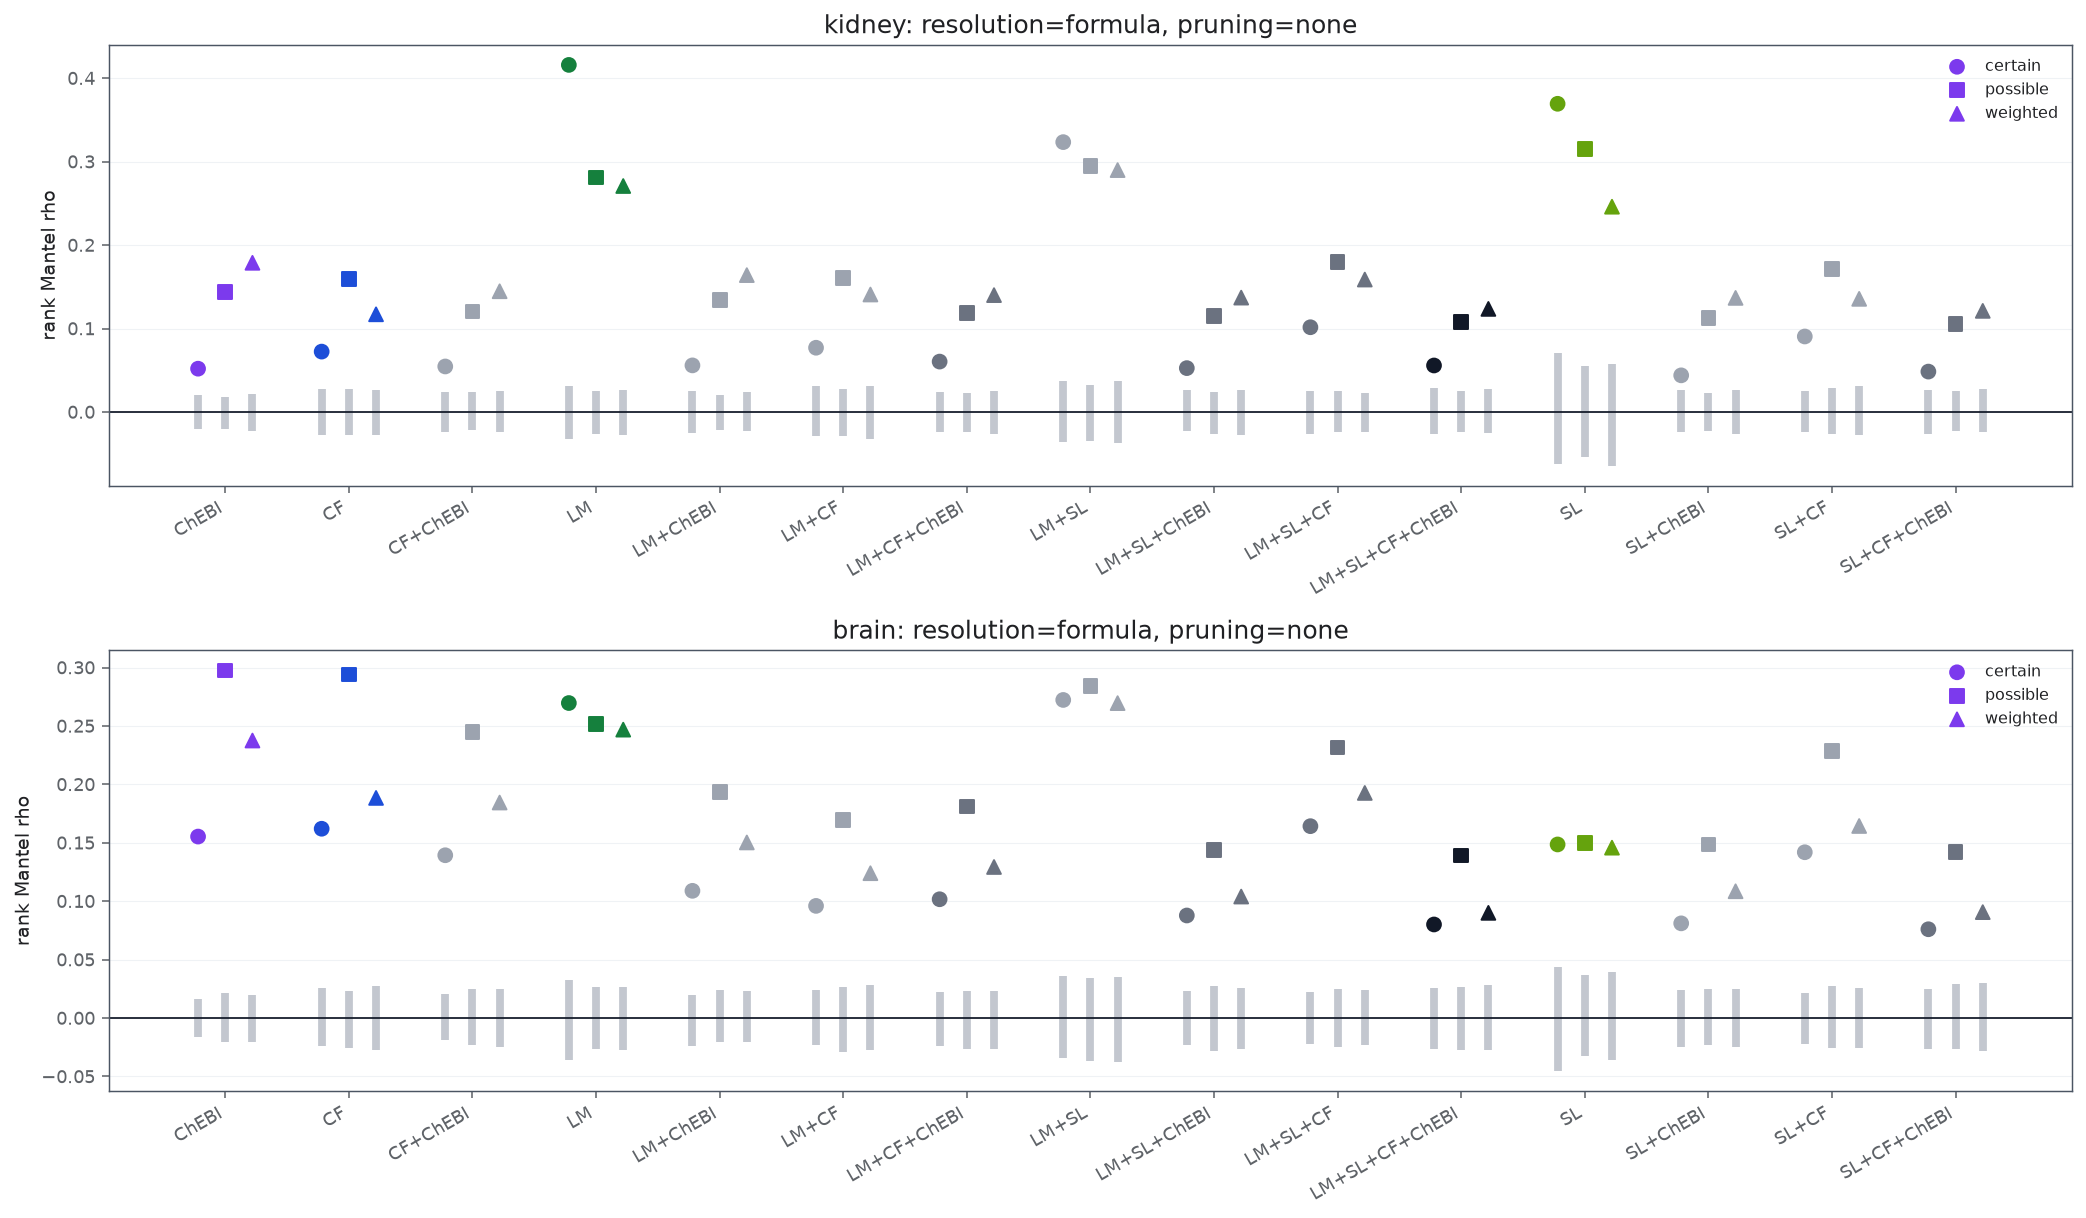

In [3]:
mantel = table("mantel.csv")

# --- what this figure shows -------------------------------------------------
RESOLUTION = "formula"
PRUNING = "none"
MARKERS = {"certain": "o", "possible": "s", "weighted": "^"}
# ---------------------------------------------------------------------------
figure, axes = plt.subplots(len(COLLECTIONS), 1, figsize=(15, 4.4 * len(COLLECTIONS)), squeeze=False)
for axis, collection in zip(axes[:, 0], COLLECTIONS):
    rows = mantel[(mantel.collection == collection) & (mantel.resolution == RESOLUTION) & (mantel.pruning == PRUNING)]
    labels = list(dict.fromkeys(rows.sort_values("taxonomies").taxonomy_label))
    for offset, (assignment, marker) in enumerate(MARKERS.items()):
        subset = rows[rows.assignment == assignment].set_index("taxonomy_label").reindex(labels)
        x = np.arange(len(labels)) + (offset - 1) * 0.22
        axis.errorbar(x, subset.null_mean, yerr=2 * subset.null_sd, fmt="none", ecolor="#9CA3AF", elinewidth=4, alpha=0.6)
        axis.scatter(x, subset.rho, marker=marker, s=50, c=[plots.taxonomy_color(l) for l in labels], label=assignment, zorder=3)
    axis.axhline(0, color=THEME.baseline_color, linewidth=THEME.reference_line_width)
    axis.set_xticks(range(len(labels)), labels, rotation=30, ha="right")
    axis.set_ylabel("rank Mantel rho")
    axis.set_title(f"{collection}: resolution={RESOLUTION}, pruning={PRUNING}")
    axis.legend(frameon=False, fontsize=8)
plt.tight_layout()
display(mantel.sort_values("rho", ascending=False).groupby("collection").head(10).round(4))

### Remarks

- All 360 tests reject $H_0$ at the smallest attainable p-value (0.005). The effect size differs strongly: with `formula`/`certain`/no pruning, $\rho$ = 0.42 (LM), 0.37 (SL), 0.32 (LM+SL) in kidney and 0.27 / 0.15 / 0.27 in brain, versus 0.04–0.16 for ClassyFire, ChEBI and every combination containing either of them.
- The tested ion populations differ between variants (lipid taxonomies resolve fewer ions), so $\rho$ values compare variants on partly different ion sets.

### Notes

## Spatial coherence of individual classes by hierarchy depth

### Methodology

#### Theoretical

For a class $c$ with member ions $M_c$, the within-class co-localization is the mean of $\bar r_{ab}$ over co-observed pairs $a,b\in M_c$; its excess over the mean of all co-observed pairs measures how spatially coherent the class is. If coherence decreases with depth, deep classes are spatially more homogeneous and coarse classes mix different tissue distributions — evidence for supervising at a specific level.

#### Implementation

`class_coherence.csv` for focus variants, classes with at least 3 member ions and at least one co-observed pair.

#### Figure descriptions

*Figure 3.* Violins of the coherence excess ($y$) per class depth ($x$) for the selected variant; each point is one class. The horizontal line at 0 is the collection-wide mean. The table lists the most and least coherent classes.

,name,depth,ions,pairs,within_mean,excess
162,Benzenesulfonic acids and derivatives,4,4,3,0.848,0.813
213,N-acyl-alpha amino acids,8,4,3,0.827,0.792
191,N-acyl-alpha amino acids and derivatives,7,4,3,0.827,0.792
199,Sulfatides,5,4,4,0.784,0.749
190,Triacylglycerols,5,10,17,0.629,0.594
220,Triradylcglycerols,4,10,17,0.629,0.594
210,Glycerophosphoglycerols,4,11,49,0.552,0.517
196,Phosphatidylglycerols,5,11,49,0.552,0.517
194,Phosphatidylinositols,5,5,10,0.523,0.488
165,Glycerolipids,3,20,56,0.458,0.422


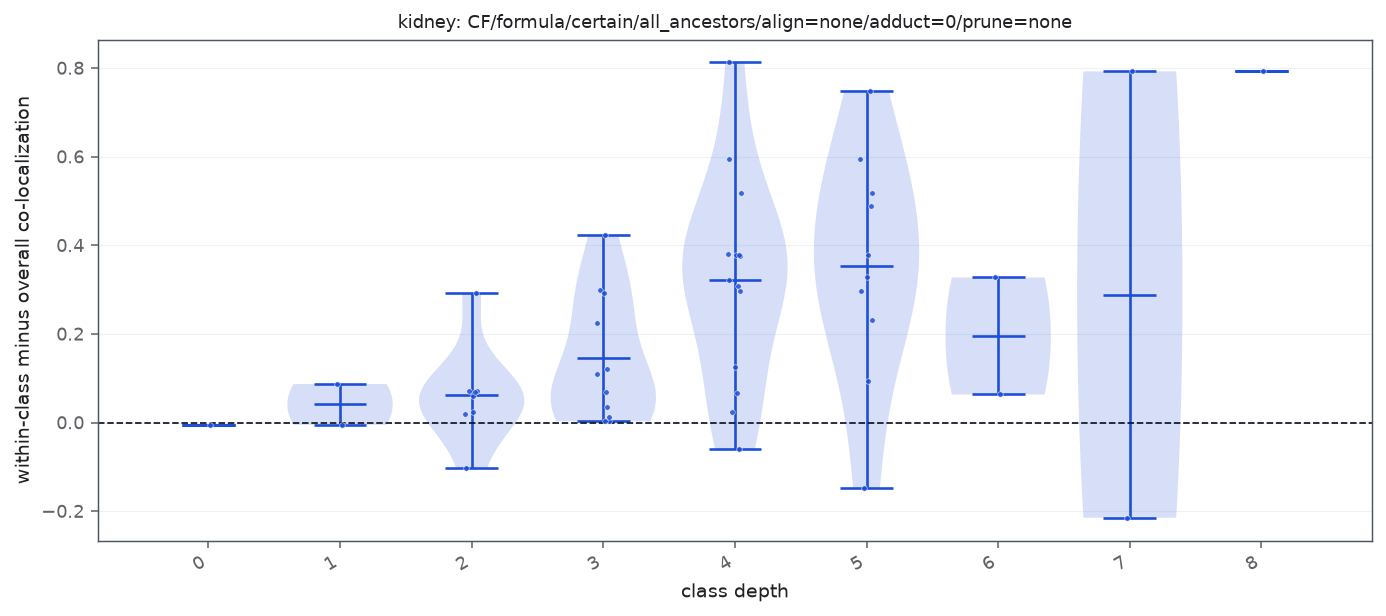

In [4]:
coherence = table("class_coherence.csv")

# --- what this figure shows -------------------------------------------------
COLLECTION = "kidney"
VARIANT = "CF/formula/certain/all_ancestors/align=none/adduct=0/prune=none"
MAX_DEPTH = 8
MIN_PAIRS = 3
# ---------------------------------------------------------------------------
rows = coherence[(coherence.collection == COLLECTION) & (coherence.variant_id == VARIANT)
                 & (coherence.depth <= MAX_DEPTH) & (coherence.pairs >= MIN_PAIRS)].assign(group=lambda f: f.depth.astype(str))
order = [str(d) for d in sorted(rows.depth.unique())]
figure, axis = plt.subplots(figsize=(10, 4.5))
plots.violin_groups(axis, rows, group="group", value="excess", order=order, reference=0.0,
                    colors={d: plots.taxonomy_color(VARIANT.split("/")[0]) for d in order}, theme=THEME)
axis.set_xlabel("class depth")
axis.set_ylabel("within-class minus overall co-localization")
axis.set_title(f"{COLLECTION}: {VARIANT}", fontsize=9)
plt.tight_layout()
ranked = rows.sort_values("excess", ascending=False)[["name", "depth", "ions", "pairs", "within_mean", "excess"]].round(3)
display(pd.concat([ranked.head(10), ranked.tail(10)]))

### Remarks

- Within-class co-localization excess increases with ClassyFire depth: ≈ 0 at the root and kingdom, median ≈ 0.15 at depth 3 and ≈ 0.3–0.35 at depths 4–5 (kidney). Deep classes such as phosphatidylglycerols, phosphatidylinositols, triacylglycerols and sulfatides are spatially coherent; broad classes such as *Organic acids and derivatives* are not.

### Notes

## Alignment of graph-propagated ion representations with co-localization

### Methodology

#### Theoretical

$\mathrm{CKA}(K_k, L)$ compares the geometry of ions after $k$ graph propagation steps with their co-localization geometry. $k=0$ gives the identity kernel (no graph), the reference level. An increase of CKA with $k$ means that propagation over the variant's relations moves ion representations toward the empirical co-localization structure; a decrease means that it mixes ions that do not co-localize (harmful coupling).

#### Implementation

`kernel_alignment.csv`: for every variant of the full grid and $k\in\{0,1,2,3\}$, $K_k$ is the cosine kernel of ion rows of $\hat A^k$ (GPU), restricted to ions annotated in at least 3 images; $L$ is the pooled co-localization matrix of the same ions with missing entries set to 0 and unit diagonal.

#### Figure descriptions

*Figure 4.* Left: CKA ($y$) versus $k$ ($x$) for selected taxonomy combinations with the remaining axes fixed (colour = combination, line style = attachment); the dotted line is the $k=0$ reference. Right: violins of CKA at the selected $k$ over all variants grouped by the selected axis; each point is one variant.

,variant_id,cka,resolved_ions,ions
742,ChEBI/formula/weighted/most_specific/align=non...,0.4041,154,164
1698,LM+ChEBI/formula/weighted/most_specific/align=...,0.4037,155,164
714,ChEBI/formula/possible/most_specific/align=non...,0.4033,154,164
706,ChEBI/formula/possible/most_specific/align=non...,0.4032,154,164
2922,CF+ChEBI/formula/possible/most_specific/align=...,0.4027,156,164
2890,CF+ChEBI/formula/possible/most_specific/align=...,0.4026,156,164
2906,CF+ChEBI/formula/possible/most_specific/align=...,0.4026,156,164
98,LM/formula/certain/most_specific/align=none/ad...,0.4025,80,164
3010,CF+ChEBI/formula/weighted/most_specific/align=...,0.4022,156,164
2978,CF+ChEBI/formula/weighted/most_specific/align=...,0.4019,156,164


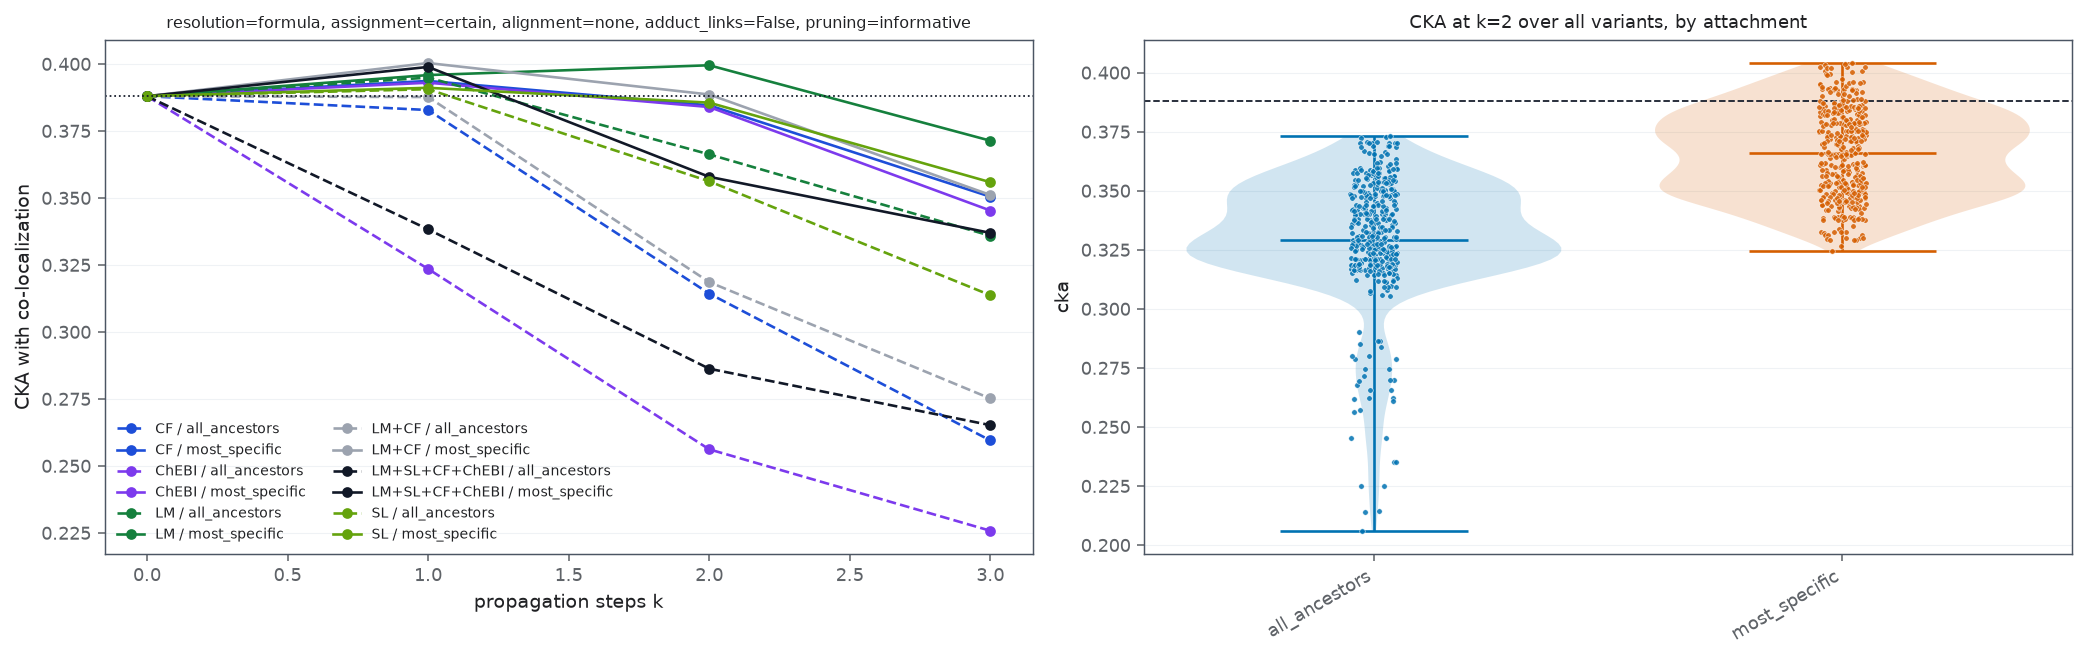

In [5]:
alignment = table("kernel_alignment.csv")
alignment["adduct_links"] = alignment.adduct_links.astype(bool)

# --- what this figure shows -------------------------------------------------
COLLECTION = "kidney"
COMBINATIONS = ["LM", "SL", "CF", "ChEBI", "LM+CF", "LM+SL+CF+ChEBI"]
FIXED = {"resolution": "formula", "assignment": "certain", "alignment": "none", "adduct_links": False, "pruning": "informative"}
STEPS = 2
AXIS = "attachment"
# ---------------------------------------------------------------------------
subset = alignment[alignment.collection == COLLECTION]
reference = float(subset.loc[subset.steps == 0, "cka"].iloc[0])
mask = np.logical_and.reduce([subset[k] == v for k, v in FIXED.items()])
figure, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for (label, attachment), rows in subset[mask & subset.taxonomy_label.isin(COMBINATIONS)].groupby(["taxonomy_label", "attachment"]):
    rows = rows.sort_values("steps")
    axes[0].plot(rows.steps, rows.cka, marker="o", color=plots.taxonomy_color(label),
                 linestyle="-" if attachment == "most_specific" else "--", label=f"{label} / {attachment}")
axes[0].axhline(reference, color=THEME.baseline_color, linestyle=":", linewidth=THEME.reference_line_width)
axes[0].set_xlabel("propagation steps k")
axes[0].set_ylabel("CKA with co-localization")
axes[0].legend(fontsize=7, frameon=False, ncols=2)
axes[0].set_title(", ".join(f"{k}={v}" for k, v in FIXED.items()), fontsize=8)
rows = subset[subset.steps == STEPS].assign(group=lambda f: f[AXIS].astype(str))
plots.violin_groups(axes[1], rows, group="group", value="cka", order=sorted(rows.group.unique()), reference=reference, theme=THEME)
axes[1].set_title(f"CKA at k={STEPS} over all variants, by {AXIS}", fontsize=9)
plt.tight_layout()
display(subset[subset.steps == STEPS].nlargest(15, "cka")[["variant_id", "cka", "resolved_ions", "ions"]].round(4))

### Remarks

- CKA without graph ($k=0$) is 0.388 (kidney, 164 ions) and 0.234 (brain, 278 ions). One propagation step raises it slightly for every variant (kidney up to 0.41, brain up to 0.27); two and three steps lower it below the reference for most variants (kidney median 0.350 at $k=2$, 0.326 at $k=3$).
- Most-specific attachment aligns better than all-ancestor attachment at $k=2$ (kidney median 0.366 vs 0.331), and alignment decreases with the number of combined taxonomies.
- The CKA population (ions in ≥ 3 images) includes unresolved ions, whose propagated embedding remains one-hot; this dilutes differences between variants.

### Notes

## Results / Summary

### LLM

**Observed.** Graph proximity is significantly associated with spatial co-localization for every variant ($p \le 0.005$ for all 360 Mantel tests), but the effect is large only for lipid taxonomies (kidney $\rho$ 0.37–0.42, brain 0.15–0.27) and small for ClassyFire, ChEBI and all combinations containing either of them (0.04–0.16). Spatial coherence of classes increases with hierarchy depth. Propagation helps alignment with co-localization only for one step and hurts it for two or more steps, especially with all-ancestor attachment and many combined taxonomies.

**Interpretation.** The chemical relations that agree with MSI spatial structure are the specific lipid-class relations (LIPID MAPS / SwissLipids), not the generic structural classes of ChEBI or upper ClassyFire levels. Coupling classifiers through a graph is therefore justified for specific classes and shallow propagation (one, at most two layers) with most-specific attachment; deep propagation or generic hubs would couple ions that do not co-localize.

**Caveats.** Effects are associations at the population level; tested ion sets differ between variants; co-localization is pooled over images with different composition and includes one duplicated kidney image; unresolved ions dilute CKA differences.

### Person